# h01 — Human MS / Baló: do the segmentation stains report their proteins?

In mouse the boundary channel (ATP1A1 + CD45 + E-cadherin) behaved as ATP1A1 only: CD45 was undetectable, so the
kit's immune-cell marker was lost. The human panel carries the RNA for every protein in the stains (*PTPRC* = CD45,
*ATP1A1*, *CDH1* = E-cadherin, *VIM*; *ACTA2* is not on it), so here each stain can be checked against its own gene,
cell by cell:
1. **CD45.** Are immune cells (lymphocytes, myeloid cells; high *PTPRC*) brighter at their membrane in the boundary
   channel than (a) other cell types and (b) their own non-immune neighbours at the same spot? Does membrane
   brightness rise with *PTPRC* within immune cells?
2. **ATP1A1, E-cadherin, vimentin.** Per cell type, does the channel follow the gene's RNA?
3. **Seeing it.** Random immune cells next to random oligodendrocytes, boundary channel and DAPI.

Data: 4 sections (MS spinal cord S07-256, S13-019; Baló Balo-1, Balo-2), one run. Cell types: marker + manual
labels (`human/scripts/01_label_clusters.py`); "low quality" cells excluded. Image features: the mouse pipeline
(`scripts/01_extract_features.py --config human/config.yaml`), raw intensities, compared **within section**.
Policy: no per-cell data leaves the analysis Mac; figures and summary tables only.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.spatial import cKDTree
from scipy.stats import spearmanr, wilcoxon
from skimage.segmentation import find_boundaries

from beyondboundaries import plotting
from beyondboundaries.io import XeniumBundle, find_bundles

plotting.style()
SRC = "human/notebooks/h01_stains_vs_rna.ipynb"
OUT = ROOT / "human" / "results" / "h01_stains_vs_rna"
OUT.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load(open(ROOT / "human" / "config.yaml"))
IMMUNE = ["Lymphocyte (T/B/plasma)", "Myeloid", "Myeloid (SPP1+ activated)"]
GENES = ["PTPRC", "ATP1A1", "CDH1", "VIM", "GFAP", "CD3E", "CD68", "P2RY12", "CD163"]
SAMPLES = ["S07-256", "S13-019", "Balo-1", "Balo-2"]

In [2]:
a = ad.read_h5ad(CFG["annotation"]["h5ad"], backed="r")
ct = pd.read_parquet(ROOT / "human" / "data" / "cell_types.parquet")
cnt = a[:, GENES].to_memory().layers["counts"]
cnt = pd.DataFrame(cnt.toarray() if hasattr(cnt, "toarray") else cnt, index=a.obs_names, columns=GENES)
cells = ct.join(cnt).join(a.obs[["total_counts"]])
a.file.close()
cells = cells[cells.cell_type != "low quality"]
bundles = find_bundles(CFG)
sec_of = {sid.split("_")[1]: sid for sid in bundles}
feats = []
for smp, sid in sec_of.items():
    f = pd.read_parquet(ROOT / CFG["features_dir"] / f"{sid}.parquet")
    if "cell_id" not in f.columns:
        f = f.reset_index()
    f["sample_id"] = smp
    feats.append(f.reset_index(drop=True))
feats = pd.concat(feats)
d = cells.reset_index().merge(feats.drop(columns=["x_centroid", "y_centroid", "segmentation_method"]),
                              on=["sample_id", "cell_id"], how="inner").set_index("index")
for ch in ["bnd", "smavim", "r18s", "dapi"]:
    d[f"{ch}_rim_contrast"] = np.log(d[f"{ch}_rim_mean"].clip(lower=1) / d[f"{ch}_ring_mean"].clip(lower=1))
    g = d.groupby("sample_id")[f"{ch}_cell_mean"]
    d[f"{ch}_z"] = (d[f"{ch}_cell_mean"] - g.transform("median")) / (
        (d[f"{ch}_cell_mean"] - g.transform("median")).abs().groupby(d.sample_id).transform("median") * 1.4826)
d["immune"] = d.cell_type.isin(IMMUNE)
for gname in GENES:
    d[f"{gname}_per1k"] = d[gname] / d.total_counts.clip(lower=1) * 1000
print(f"{len(d):,} cells with features;", d.groupby("sample_id").size().to_dict())
pd.crosstab(d.cell_type, d.sample_id)

253,060 cells with features; {'Balo-1': 25421, 'Balo-2': 35756, 'S07-256': 101913, 'S13-019': 89970}


sample_id,Balo-1,Balo-2,S07-256,S13-019
cell_type,,,,
Astrocyte,5420,5234,8346,14170
Astrocyte (reactive),3,16,9065,224
Endothelial,21,66,7296,3688
Ependymal,21,16,651,785
Fibroblast,130,46,7345,5093
Lymphocyte (T/B/plasma),121,142,2570,7085
Myeloid,48,101,18404,19801
Myeloid (SPP1+ activated),2669,9146,40,16
Neuron,10272,4451,2434,1382


## 1. CD45: are immune cells brighter at the membrane in the boundary channel?
Two readouts per cell: **membrane contrast** = log(rim mean / ring mean), the cell's outline against the 2 µm just
outside it (CD45 sits in the membrane, neuropil ATP1A1 around it), and the **cell mean** (robust z within the
section). Per section and cell type: median. Positive membrane contrast in immune cells, but not in their
neighbours, would be CD45.

In [3]:
tab = d.groupby(["cell_type", "sample_id"]).agg(cells=("bnd_rim_contrast", "size"),
                                                membrane_contrast=("bnd_rim_contrast", "median"),
                                                cell_mean_z=("bnd_z", "median"),
                                                PTPRC_per1k=("PTPRC_per1k", "mean")).round(3)
tab = tab[tab.cells >= 30]
tab.to_csv(OUT / "boundary_channel_by_celltype.csv")
tab.unstack("sample_id")["membrane_contrast"].sort_values("S13-019", ascending=False)

sample_id,Balo-1,Balo-2,S07-256,S13-019
cell_type,,,,
Lymphocyte (T/B/plasma),1.097,0.772,0.754,0.609
Myeloid,0.056,0.052,0.428,0.387
Fibroblast,0.747,0.314,0.320,0.366
Perivascular (mixed),NaN,0.079,0.450,0.325
Ependymal,NaN,NaN,0.506,0.314
Endothelial,NaN,-0.068,0.427,0.299
Schwann,NaN,NaN,0.210,0.184
Pericyte / VSMC,0.423,0.274,0.233,0.173
Astrocyte (reactive),NaN,NaN,0.075,0.043


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h01_stains_vs_rna/boundary_channel_by_celltype.png')

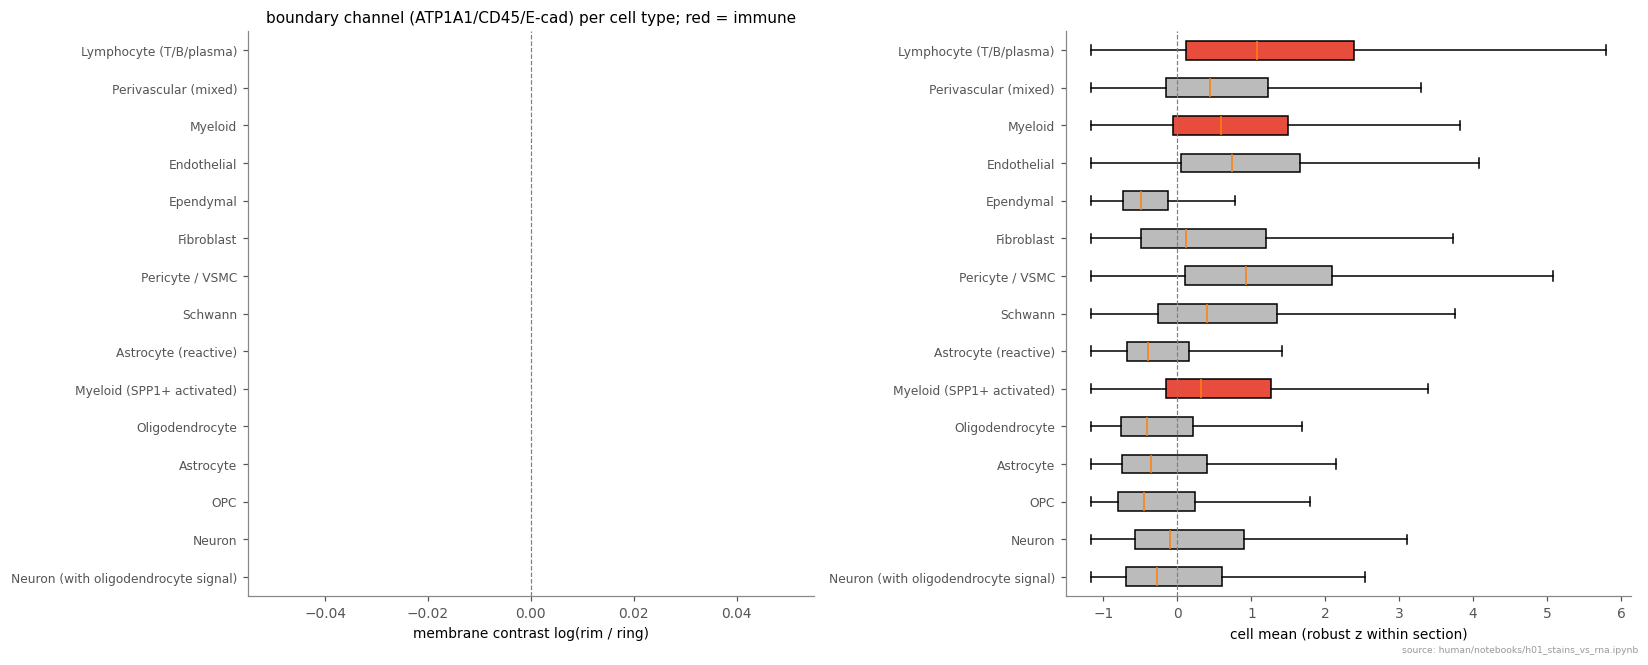

In [4]:
order = d.groupby("cell_type").bnd_rim_contrast.median().sort_values().index
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, col, lab in [(axs[0], "bnd_rim_contrast", "membrane contrast log(rim / ring)"),
                     (axs[1], "bnd_z", "cell mean (robust z within section)")]:
    data = [d.loc[d.cell_type == t, col].clip(*d[col].quantile([0.01, 0.99])) for t in order]
    bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True)
    for patch, t in zip(bp["boxes"], order):
        patch.set_facecolor("#e74c3c" if t in IMMUNE else "#bbbbbb")
    ax.set_yticks(range(1, len(order) + 1), order, fontsize=8)
    ax.axvline(0, color="0.5", lw=0.8, ls="--")
    ax.set_xlabel(lab)
axs[0].set_title("boundary channel (ATP1A1/CD45/E-cad) per cell type; red = immune")
fig.tight_layout()
plotting.save_fig(fig, "boundary_channel_by_celltype", OUT, SRC)

**Paired with the neighbour.** Each immune cell against its nearest non-immune cell of the same section (within
30 µm), so neuropil and tissue brightness are shared: the immune − neighbour difference in membrane contrast and in
cell mean, per section (median, share of pairs where the immune cell is brighter, Wilcoxon). Control: the same for
oligodendrocytes paired with their nearest non-oligodendrocyte.

In [5]:
def paired(d, focal, label):
    rows = []
    for smp, g in d.groupby("sample_id"):
        F, O = g[focal(g)], g[~focal(g)]
        if len(F) < 30:
            continue
        dist, idx = cKDTree(O[["x_centroid", "y_centroid"]].to_numpy()).query(F[["x_centroid", "y_centroid"]].to_numpy())
        ok = dist <= 30
        for col, nm in [("bnd_rim_contrast", "membrane contrast"), ("bnd_z", "cell mean z")]:
            diff = F[col].to_numpy()[ok] - O[col].to_numpy()[idx[ok]]
            diff = diff[np.isfinite(diff)]
            rows.append(dict(focal=label, sample=smp, readout=nm, pairs=int(ok.sum()), median_diff=np.median(diff),
                             share_brighter=(diff > 0).mean(), p=wilcoxon(diff).pvalue))
    return rows


pr = pd.DataFrame(paired(d, lambda g: g.cell_type == "Lymphocyte (T/B/plasma)", "lymphocytes")
                  + paired(d, lambda g: g.cell_type.isin(["Myeloid", "Myeloid (SPP1+ activated)"]), "myeloid")
                  + paired(d, lambda g: g.cell_type == "Oligodendrocyte", "oligodendrocytes (control)"))
pr.round(4).to_csv(OUT / "immune_vs_neighbour.csv", index=False)
pr.round(3)

,focal,sample,readout,pairs,median_diff,share_brighter,p
0,lymphocytes,Balo-1,membrane contrast,70,0.594,0.783,0.000
1,lymphocytes,Balo-1,cell mean z,70,0.615,0.657,0.002
2,lymphocytes,Balo-2,membrane contrast,127,0.652,0.874,0.000
3,lymphocytes,Balo-2,cell mean z,127,2.315,0.913,0.000
4,lymphocytes,S07-256,membrane contrast,2469,0.342,0.712,0.000
5,lymphocytes,S07-256,cell mean z,2469,0.521,0.696,0.000
6,lymphocytes,S13-019,membrane contrast,6885,0.267,0.670,0.000
7,lymphocytes,S13-019,cell mean z,6885,0.470,0.646,0.000
8,myeloid,Balo-1,membrane contrast,2476,0.094,0.714,0.000
9,myeloid,Balo-1,cell mean z,2476,0.422,0.778,0.000


**Dose–response within immune cells.** If the boundary channel carries CD45, membrane contrast should rise with
*PTPRC* RNA (per 1,000 transcripts) across immune cells of the same section. Spearman per section and immune type;
control: the same against *ATP1A1* RNA.

In [6]:
rows = []
for smp, g in d.groupby("sample_id"):
    for t in IMMUNE:
        s = g[g.cell_type == t]
        if len(s) < 50:
            continue
        for gene in ["PTPRC", "ATP1A1"]:
            x = s[[f"{gene}_per1k", "bnd_rim_contrast"]].replace([np.inf, -np.inf], np.nan).dropna()
            r = spearmanr(x.iloc[:, 0], x.iloc[:, 1])
            rows.append(dict(sample=smp, cell_type=t, gene=gene, cells=len(s), rho=r.statistic, p=r.pvalue))
dose = pd.DataFrame(rows)
dose.round(4).to_csv(OUT / "ptprc_dose_response.csv", index=False)
dose.round(3)

,sample,cell_type,gene,cells,rho,p
0,Balo-1,Lymphocyte (T/B/plasma),PTPRC,121,0.113,0.217
1,Balo-1,Lymphocyte (T/B/plasma),ATP1A1,121,-0.007,0.941
2,Balo-1,Myeloid (SPP1+ activated),PTPRC,2669,0.002,0.931
3,Balo-1,Myeloid (SPP1+ activated),ATP1A1,2669,-0.043,0.026
4,Balo-2,Lymphocyte (T/B/plasma),PTPRC,142,0.079,0.351
5,Balo-2,Lymphocyte (T/B/plasma),ATP1A1,142,0.049,0.563
6,Balo-2,Myeloid,PTPRC,101,-0.178,0.076
7,Balo-2,Myeloid,ATP1A1,101,0.199,0.047
8,Balo-2,Myeloid (SPP1+ activated),PTPRC,9146,0.017,0.112
9,Balo-2,Myeloid (SPP1+ activated),ATP1A1,9146,-0.004,0.732


### Is it CD45 or geometry?
Lymphocytes are small with little cytoplasm, so their outline hugs the nucleus and the 2 µm ring around them can
catch neighbours; in mouse, a T-cell "polarity" turned out to be geometry plus bleed (notebook 19). Two controls:
1. **Other channels:** the same membrane contrast in DAPI, 18S and αSMA/vimentin. CD45 should raise it in the
   boundary channel only.
2. **Size-matched:** lymphocytes against non-immune cells of the same cell-area decile, same section.

In [7]:
rows = []
for smp, g in d.groupby("sample_id"):
    for t in ["Lymphocyte (T/B/plasma)", "Myeloid", "Oligodendrocyte", "Astrocyte", "Endothelial"]:
        s_ = g[g.cell_type == t]
        if len(s_) < 50:
            continue
        rows.append(dict(sample=smp, cell_type=t, cells=len(s_),
                         **{ch: s_[f"{ch}_rim_contrast"].median() for ch in ["bnd", "dapi", "r18s", "smavim"]}))
geo = pd.DataFrame(rows)
geo.round(3).to_csv(OUT / "membrane_contrast_all_channels.csv", index=False)
print("membrane contrast log(rim / ring), median per section and type")
geo.round(2)

membrane contrast log(rim / ring), median per section and type


,sample,cell_type,cells,bnd,dapi,r18s,smavim
0,Balo-1,Lymphocyte (T/B/plasma),121,1.10,2.15,2.45,0.98
1,Balo-1,Oligodendrocyte,3288,-0.09,1.60,1.20,-0.05
2,Balo-1,Astrocyte,5420,-0.13,0.85,0.56,0.48
3,Balo-2,Lymphocyte (T/B/plasma),142,0.77,1.97,1.29,0.68
4,Balo-2,Myeloid,101,0.05,1.59,0.77,0.26
5,Balo-2,Oligodendrocyte,13614,0.03,1.41,1.13,-0.02
6,Balo-2,Astrocyte,5234,-0.05,0.75,0.67,0.46
7,Balo-2,Endothelial,66,-0.07,1.71,1.08,0.49
8,S07-256,Lymphocyte (T/B/plasma),2570,0.75,2.51,1.48,0.87
9,S07-256,Myeloid,18404,0.43,2.75,1.31,0.05


In [8]:
rows = []
for smp, g in d.groupby("sample_id"):
    g = g.assign(size_dec=pd.qcut(g.cell_area.rank(method="first"), 10, labels=False))
    for dec, gd in g.groupby("size_dec"):
        L, N = gd[gd.cell_type == "Lymphocyte (T/B/plasma)"], gd[~gd.immune]
        if len(L) >= 20 and len(N) >= 20:
            for ch in ["bnd", "dapi", "r18s"]:
                rows.append(dict(sample=smp, size_decile=dec, channel=ch, lymphocytes=len(L),
                                 diff=L[f"{ch}_rim_contrast"].median() - N[f"{ch}_rim_contrast"].median()))
sm = pd.DataFrame(rows)
smt = sm.groupby(["sample", "channel"]).agg(deciles=("diff", "size"), median_diff=("diff", "median"),
                                            deciles_positive=("diff", lambda x: (x > 0).mean())).round(3)
smt.to_csv(OUT / "size_matched_lymphocyte_contrast.csv")
smt

deciles  median_diff  deciles_positive
sample  channel                                        
Balo-1  bnd            2        1.533               1.0
        dapi           2        1.110               1.0
        r18s           2        1.888               1.0
Balo-2  bnd            2        0.797               1.0
        dapi           2        0.619               1.0
        r18s           2        0.191               1.0
S07-256 bnd           10        0.636               1.0
        dapi          10       -0.249               0.2
        r18s          10        0.005               0.5
S13-019 bnd           10        0.569               1.0
        dapi          10       -0.477               0.2
        r18s          10        0.091               0.8

## 2. Each stain against its own gene's RNA, per cell type
Per section, the cell-type median of the channel (robust z) against the cell-type mean RNA (per 1,000
transcripts) of the matching gene: boundary channel vs *ATP1A1*, *PTPRC* and *CDH1*; αSMA/vimentin channel vs *VIM*.
Spearman over cell types (≥ 30 cells), per section.

In [9]:
rows, pts = [], []
for smp, g in d.groupby("sample_id"):
    agg = g.groupby("cell_type").agg(n=("bnd_z", "size"), bnd=("bnd_z", "median"), smavim=("smavim_z", "median"),
                                     **{gn: (f"{gn}_per1k", "mean") for gn in ["ATP1A1", "PTPRC", "CDH1", "VIM"]})
    agg = agg[agg.n >= 30]
    for ch, gene in [("bnd", "ATP1A1"), ("bnd", "PTPRC"), ("bnd", "CDH1"), ("smavim", "VIM")]:
        r = spearmanr(agg[ch], agg[gene])
        rows.append(dict(sample=smp, channel=ch, gene=gene, cell_types=len(agg), rho=r.statistic, p=r.pvalue))
    pts.append(agg.assign(sample=smp))
st = pd.DataFrame(rows)
st.round(3).to_csv(OUT / "stain_vs_gene_by_celltype.csv", index=False)
pts = pd.concat(pts)
st.pivot(index=["channel", "gene"], columns="sample", values="rho").round(2)

sample          Balo-1  Balo-2  S07-256  S13-019
channel gene                                    
bnd     ATP1A1   -0.56    0.02     0.23    -0.49
        CDH1     -0.05    0.24    -0.24    -0.26
        PTPRC     0.44    0.53     0.27     0.53
smavim  VIM       0.98    0.93     0.92     0.69

PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h01_stains_vs_rna/stain_vs_gene_by_celltype.png')

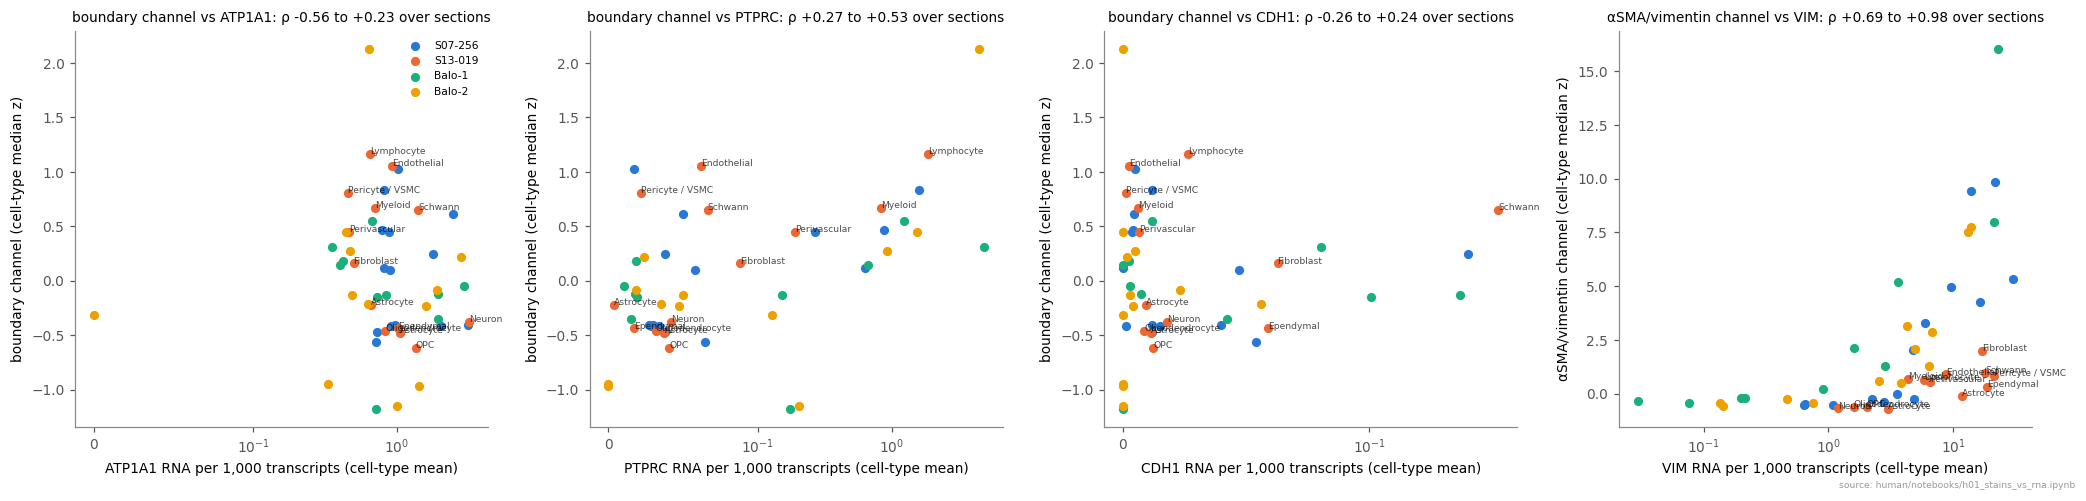

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(19, 4.5))
for ax, (ch, gene, lab) in zip(axs, [("bnd", "ATP1A1", "boundary channel"), ("bnd", "PTPRC", "boundary channel"),
                                     ("bnd", "CDH1", "boundary channel"), ("smavim", "VIM", "αSMA/vimentin channel")]):
    for k, smp in enumerate(SAMPLES):
        p_ = pts[pts["sample"] == smp]
        ax.scatter(p_[gene], p_[ch], s=25, color=plotting.CATEGORICAL[k], label=smp)
        if smp == "S13-019":
            for t, r in p_.iterrows():
                ax.annotate(t.split(" (")[0], (r[gene], r[ch]), fontsize=6, alpha=0.7)
    rr = st[(st.channel == ch) & (st.gene == gene)].rho
    ax.set_xscale("symlog", linthresh=0.1)
    ax.set_xlabel(f"{gene} RNA per 1,000 transcripts (cell-type mean)")
    ax.set_ylabel(f"{lab} (cell-type median z)")
    ax.set_title(f"{lab} vs {gene}: ρ {rr.min():+.2f} to {rr.max():+.2f} over sections", fontsize=9)
axs[0].legend(fontsize=7)
fig.tight_layout()
plotting.save_fig(fig, "stain_vs_gene_by_celltype", OUT, SRC)

## 3. Seeing it
Random lymphocytes, random myeloid cells and random oligodendrocytes (one per row block, 6 each, seed 0) from the
two MS sections: the boundary channel (top of each pair) and DAPI, 30 µm crops, the focal cell outlined in cyan,
other outlines grey. Same display range per section (1st–99.5th percentile of tissue pixels).

PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h01_stains_vs_rna/gallery_immune_vs_oligo.png')

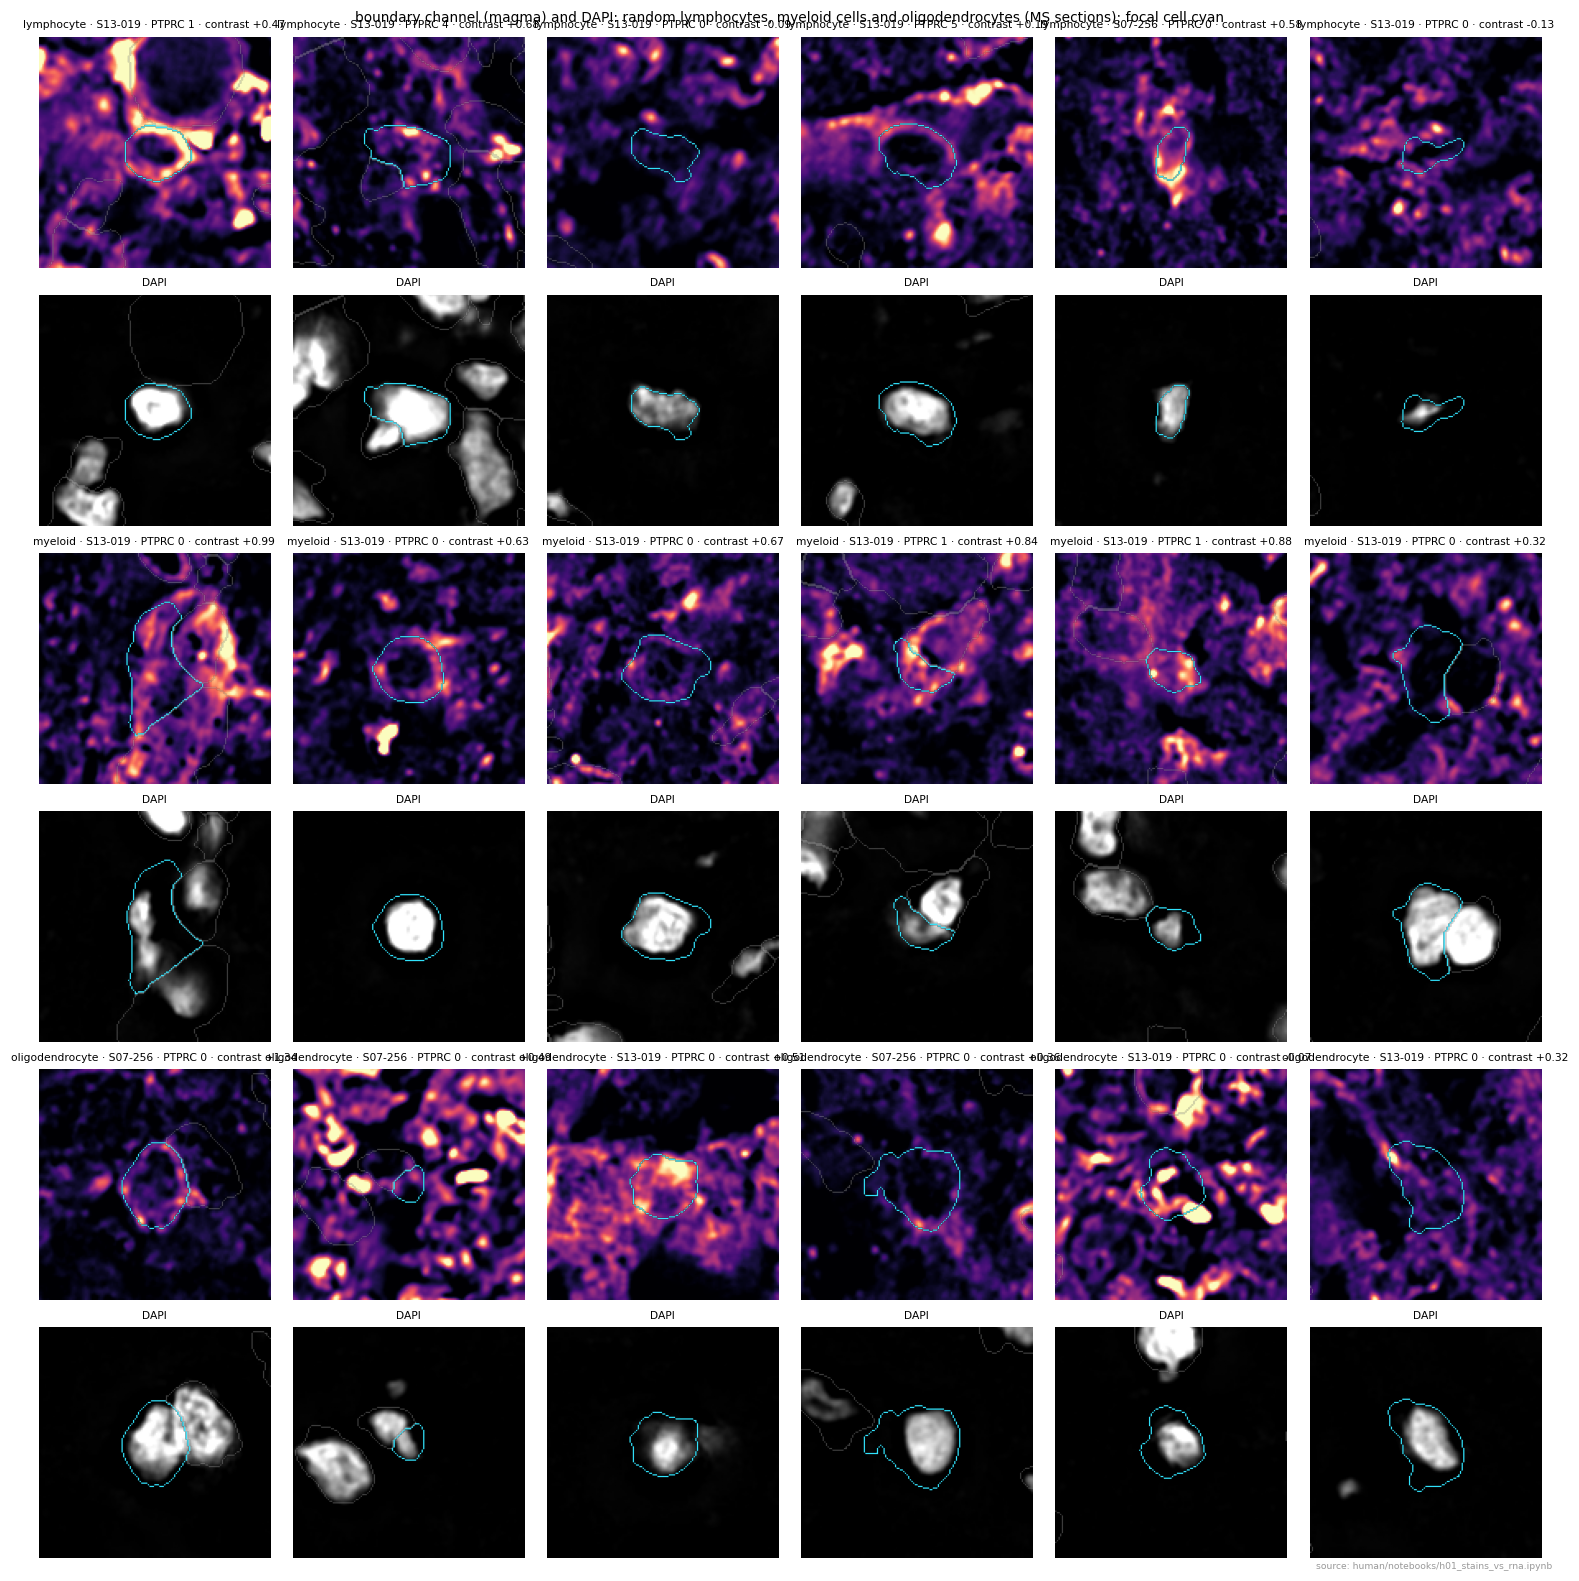

In [11]:
_B, _R = {}, {}


def bundle(smp):
    if smp not in _B:
        _B[smp] = XeniumBundle(bundles[sec_of[smp]])
    return _B[smp]


def drange(smp, ch):
    if (smp, ch) not in _R:
        im = bundle(smp).read_level(ch, 3).astype(np.float32)
        v = im[im > 0]
        _R[(smp, ch)] = (np.percentile(v, 1), np.percentile(v, 99.5))
    return _R[(smp, ch)]


def crop(ax, r, ch_i, ch, w_um=30, title=""):
    b = bundle(r.sample_id)
    px = b.pixel_size
    y0, x0 = int(r.centroid_y_px - w_um / 2 / px), int(r.centroid_x_px - w_um / 2 / px)
    img, lab, _ = b.read_window(y0, x0, int(w_um / px), int(w_um / px))
    lo, hi = drange(r.sample_id, ch)
    ax.imshow(np.clip((img[ch_i] - lo) / (hi - lo), 0, 1), cmap="magma" if ch == "bnd" else "gray")
    e = find_boundaries(lab, mode="inner")
    ov = np.zeros((*lab.shape, 4))
    ov[e] = (0.6, 0.6, 0.6, 0.4)
    ov[e & (lab == r.label)] = (0.2, 0.9, 1, 1)
    ax.imshow(ov)
    ax.set_title(title, fontsize=7)
    ax.axis("off")


rng = np.random.default_rng(0)
groups = [("lymphocyte", d.cell_type == "Lymphocyte (T/B/plasma)"), ("myeloid", d.cell_type == "Myeloid"),
          ("oligodendrocyte", d.cell_type == "Oligodendrocyte")]
fig, axs = plt.subplots(6, 6, figsize=(14, 14.5))
for gi, (nm, m) in enumerate(groups):
    s = d[m & d.sample_id.isin(["S07-256", "S13-019"])]
    pick = s.iloc[rng.choice(len(s), 6, replace=False)]
    for j, (_, r) in enumerate(pick.iterrows()):
        crop(axs[2 * gi, j], r, 1, "bnd", title=f"{nm} · {r.sample_id} · PTPRC {int(r.PTPRC)} · contrast {r.bnd_rim_contrast:+.2f}")
        crop(axs[2 * gi + 1, j], r, 0, "dapi", title="DAPI")
fig.suptitle("boundary channel (magma) and DAPI: random lymphocytes, myeloid cells and oligodendrocytes (MS sections); "
             "focal cell cyan", fontsize=9)
fig.tight_layout()
plotting.save_fig(fig, "gallery_immune_vs_oligo", OUT, SRC)

## Findings

> **CD45 is detectable in human MS lymphocytes — unlike in mouse (moderate, MS sections).** In both MS sections
> lymphocytes have the highest boundary-channel membrane contrast of any cell type (log rim ÷ ring 0.61–0.75 vs ≈ 0
> for glia), are brighter at the membrane than their nearest non-immune neighbour in 67–71 % of 2,469–6,885 pairs,
> and stay brighter at **matched cell size** (+0.57 to +0.64, 10 of 10 size deciles) while DAPI (−0.25 to −0.48,
> 2/10) and 18S (≈ 0) do not: a boundary-channel-specific membrane signal, not outline geometry. Within lymphocytes
> it rises with *PTPRC* RNA (ρ +0.13, +0.19, p < 0.001) but not with *ATP1A1* RNA (+0.08, +0.01). Myeloid cells show a
> weaker signal (+0.24 to +0.26 vs neighbours; *PTPRC* ρ +0.02), as expected for CD45-low microglia. In the images,
> some lymphocytes have a clear bright membrane ring and many do not. In the Baló sections lymphocytes are too few
> (121, 142) and DAPI/18S rise with them, so CD45 cannot be separated from geometry there.
>
> **The αSMA/vimentin channel reports vimentin (strong).** Across cell types it follows *VIM* RNA in every section
> (ρ 0.69–0.98; *ACTA2* is not on the panel). This validates the vimentin readouts used in mouse.
>
> **The boundary channel does not follow *ATP1A1* RNA across cell types** (ρ −0.56 to +0.23): ATP1A1 protein sits
> in neuropil membranes, away from the cell bodies that make the RNA, as in mouse. E-cadherin (*CDH1*) is not
> detectable (ρ −0.26 to +0.24). Endothelial cells also show a raised boundary-channel membrane contrast
> (0.30–0.43), not explained here.